In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE

today = date.today()

In [2]:
def factor_prod_ranks(roi_percents, percents, target_factors, top_regions):
    # init array
    prod_ranks = np.zeros(top_regions.shape)
    # rank values for each of the similar regions at each detail level
    sim_percents = percents[top_regions[:, 1:]]

    for dl in range(1, len(target_factors) + 1):
        # product of factor ranks for query at detail level
        query_prod = np.prod(roi_percents[target_factors[:dl]])
        # product of factor ranks for similar regions at detail level
        sim_prod = np.prod(sim_percents[dl-1][:, target_factors[:dl]], axis=1)
        # product of factor ranks for search space at detail level
        search_space_prod = np.prod(percents[:, target_factors[:dl]], axis=1)

        # rank query
        query_prod_rank = stats.percentileofscore(search_space_prod, query_prod, kind='strict')
        # rank similar regions
        sim_prod_ranks = stats.percentileofscore(search_space_prod, sim_prod, kind='strict')

        # add ranks to array
        prod_ranks[dl - 1][0] = query_prod_rank
        prod_ranks[dl - 1][1:] = sim_prod_ranks
    return prod_ranks


def setup_included_factors(included_factors_str, query_factor_thresh, roi_percents):
#     global included_factors
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]
    included_factors = included_factors[
        np.isin(included_factors, query_factors_above_thresh)
    ]
    return included_factors

# def load_roi(genomic_location, gz_file_path):
#     # determine roi from hdf5 scale file
#     query_start_end = genomic_location.split(':')[1].split('-')
#     query_start = int(query_start_end[0])
#     query_end = int(query_start_end[1])

#     gz_tb = tabix.open(gz_file_path)
#     possible_coords = np.array(list(gz_tb.querys(genomic_location)))

#     start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
#     end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)

#     query_region = possible_coords[np.argmin(start_dist + end_dist)]

#     roi = int(query_region[3])
#     return roi

def roiURL(roi, top_regions, detail_level, method, scale,
           link_type='dual'):
    today = date.today()
    roiurl_name = ('region_narration_simsearch_regions_roi_' + str(roi) +
                   '_detail_level_' + str(detail_level) + '_' + method + 
                   '_scale_' + scale + 'kb_CT' +
                   today.strftime("%Y%m%d") + '.bed')
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path1 = ('https://epilogos.altius.org:1234/?application=viewer&' +
                  'sampleSet=vC&mode=single&genome=hg38&model=18&complex' +
                  'ity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=800' +
                  '0&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%' +
                  '40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path2 = ('https://index.altius.org:1234/?application=viewer&mod' +
                  'e=pd&chrLeft=chr11&chrRight=chr11&start=47329800&stop' +
                  '=47356800&roiURL=https%3A%2F%2Fencode%3Acollabor8%40r' +
                  'esources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path_dual = ('https://index.altius.org:3000/?application=viewer' +
                      '&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8' +
                      '%40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    if link_type == 'dual':
        return link_path_dual
    else:
        return link_path1, link_path2
    
def top_region_sig(percents, top_regions):
    # mean and std of factor percentiles in all regions
    all_mean = np.mean(percents, axis=0)
    all_std = np.std(percents, axis=0)

    # mean of factor percentiles in most similar regions
    top_region_mean = np.mean(percents[top_regions[:, 1:]], axis=1)

    # Z score
    Z = (top_region_mean - all_mean) / (all_std / np.sqrt(top_regions.shape[1] - 1))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z
    
def simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]
    print(target_factors.shape)

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
#     roi_conv_all = percents[:, target_factors] * roi_percents_targeted
    roi_conv_all = ((percents[:, target_factors] * 2) - 1) * ((roi_percents_targeted * 2) - 1)

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords


    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
            num_overlaps = np.count_nonzero(
                (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
                (
                    (
                        (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                    )
                )
            )
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    print(target_factors)
#     query_sim_prod_ranks = factor_prod_ranks(roi_percents, percents, target_factors, top_regions)
    query_sim_prod_ranks = factor_sum_ranks(roi_percents, percents, target_factors, top_regions)
    
    # factor percentile significance
    pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per, query_sim_prod_ranks, pval, Z)


def factor_sum_ranks(roi_percents, percents, target_factors, top_regions):
    # init array
    sum_ranks = np.zeros(top_regions.shape)
    # rank values for each of the similar regions at each detail level
    sim_percents = percents[top_regions[:, 1:]]

    for dl in range(1, len(target_factors) + 1):
        # fusion of factor ranks for query at detail level
        query_sum = np.sum(roi_percents[target_factors[:dl]])
        # fusion of factor ranks for similar regions at detail level
        sim_sum = np.sum(sim_percents[dl-1][:, target_factors[:dl]], axis=1)
        # fusion of factor ranks for search space at detail level
        search_space_sum = np.sum(percents[:, target_factors[:dl]], axis=1)

        # rank query
        query_sum_rank = stats.percentileofscore(search_space_sum, query_sum, kind='strict')
        # rank similar regions
        sim_sum_ranks = stats.percentileofscore(search_space_sum, sim_sum, kind='strict')

        # add ranks to array
        sum_ranks[dl - 1][0] = query_sum_rank
        sum_ranks[dl - 1][1:] = sim_sum_ranks
    return sum_ranks

In [2]:
def load_factors(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return factors, color

datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_1kb_CT20230427.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_1kb_CT20230427.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_factors, DHS_color = load_factors(DHS_per_f)
epi_factors, epi_color = load_factors(epi_per_f)

factor_order = np.append(DHS_factors, epi_factors)
color_order = np.append(DHS_color, epi_color)

color_order[np.where(factor_order == 'Quies')[0]] = '#e0e0e0'

In [46]:
scale = '25'
genomic_location = 'chrX:48778015-48802844'
gene = 'GATA1'
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) +']'
query_factor_thresh = 0.5

In [47]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
sub_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

percents_sub = np.load(sub_path)['percentiles']
coords_sub = np.load(sub_path)['coordinates']
chosen_factors_sub = np.load(sub_path, allow_pickle=True)['factors']

In [48]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'

gz_file_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230412.sorted.rownum4.bed.gz'

roi = load_roi(genomic_location, gz_file_path)

In [49]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'

query_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

hdf5_f = h5py.File(query_path, 'r')
roi_percents = hdf5_f['percentiles'][roi]
roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)

s = simsearch(roi_percents, 
              percents_sub, 
              roi, 
              roi_coords, 
              coords_sub, 
              included_factors,
              num_similar_regions)

roiurls_s = []
for dl in range(included_factors.shape[0]):
    roiurls_sub.append(roiURL(roi, s[1][dl], dl+1, 'top_1000', scale))

(20,)
[15  2  9 16  8 18 19  1 17  0 11  5  3  6  7 12 24 13  4 25]


In [62]:
dl = -1
regionset_ranks = s[3][dl, 1:]
regionset_z = s[6][dl, 1:]

**Use GWAS dataset to get a set of regions**

In [4]:
def target_region_sig(ranks, target_region_ranks):
    # mean and std of factor ranks in search space
    all_mean = np.mean(ranks, axis=0)
    all_std = np.std(ranks, axis=0)

    # mean of factor ranks in target regions
    target_region_mean = np.mean(target_region_ranks, axis=0)

    # Z score
    Z = (target_region_mean - all_mean) / (all_std / np.sqrt(target_region_ranks.shape[0]))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z

In [5]:
GWAS_f = '/home/nasi4/proj/GWAS/UKBB_201807/results/all.UKBB.hg38.sig.phenotype.bed'

gwas = pd.read_csv(GWAS_f, sep='\t', names=['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'pvalue', 'phenotype'])

In [75]:
# GWAS_f = '/home/ctrader/lightfm_data/GWAS_full_dataset/UKBB_all_traits_all_sig_associations_CT20220207.bed'

# gwas = pd.read_csv(GWAS_f, sep='\t', names=['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'pvalue', 'phenotype'])

In [23]:
# traits_f = '/home/nasi4/proj/GWAS/UKBB_201807/info/phenotypes.both_sexes.tsv.gz'
# trait_codes_df = pd.read_csv(traits_f, sep='\t')

In [24]:
# def phen2description(phen):
#     des_obj = trait_codes_df[trait_codes_df['phenotype'] == str(phen)]['description']
#     return np.array(des_obj)

In [25]:
# trait_codes_df[trait_codes_df['description'].str.contains('immune', case=False, na=False)]

In [26]:
# phen2description('AD')

In [23]:
phenotypes = np.unique(gwas['phenotype'].astype(str))

In [60]:
# phenotypes[:200]

In [61]:
np.unique(gwas[gwas['phenotype'].str.contains('infarction', case=False, na=False)]['phenotype'].astype(str))

array(['Diagnoses - main ICD10 I21 Acute myocardial infarction',
       'Diagnoses - main ICD10 I22 Subsequent myocardial infarction',
       'Diagnoses - main ICD10 I63 Cerebral infarction',
       'Diagnoses - main ICD10 I64 Stroke not specified as haemorrhage or infarction',
       'Diagnoses - main ICD10 I65 Occlusion and stenosis of precerebral arteries not resulting in cerebral infarction',
       'Myocardial infarction', 'Myocardial infarction strict',
       'Non-cancer illness code self-reported heart attackmyocardial infarction',
       'Underlying primary cause of death ICD10 I21.9 Acute myocardial infarction unspecified',
       'Underlying primary cause of death ICD10 I64 Stroke not specified as haemorrhage or infarction'],
      dtype=object)

In [329]:
scale = '25'

# files
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
gz_file_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230412.sorted.rownum4.bed.gz'
query_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
sub_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

In [330]:
# search space
ranks = np.load(sub_path)['percentiles']

hdf5_f = h5py.File(query_path, 'r')
ranks_full = hdf5_f['percentiles'][:]
hdf5_f.close()

In [331]:
phen = 'Alzheimer’s disease'
phen_df = gwas[gwas['phenotype'] == phen]
phen_df = phen_df[~phen_df['Chromosome'].str.contains('_')]

In [332]:
phen_df

,Chromosome,p1,p2,Reference SNP cluster ID,pvalue,phenotype
3614,chr1,1180222,1180223,rs139755178,1.038460e-13,Alzheimer’s disease
6004,chr1,1286029,1286030,rs146233203,9.635300e-16,Alzheimer’s disease
13744,chr1,1485781,1485782,rs563153106,2.652140e-14,Alzheimer’s disease
23846,chr1,2111819,2111820,rs749900349,6.560950e-10,Alzheimer’s disease
31079,chr1,2606261,2606262,rs146150239,1.930910e-08,Alzheimer’s disease
...,...,...,...,...,...,...
16464729,chrX,145224389,145224390,rs189606920,4.607730e-08,Alzheimer’s disease
16472955,chrX,151637480,151637481,rs186999141,8.004430e-09,Alzheimer’s disease
16473001,chrX,151661634,151661635,rs775144553,3.409790e-08,Alzheimer’s disease
16478444,chrX,153897724,153897725,rs782725108,1.001860e-08,Alzheimer’s disease


In [333]:
phen_coords = np.char.add(np.array(phen_df['Chromosome']).astype(str), np.array([':'] * len(phen_df)).astype(str))
phen_coords = np.char.add(phen_coords.astype(str), np.array(phen_df['p1']).astype(str))
phen_coords = np.char.add(phen_coords.astype(str), np.array(['-'] * len(phen_df)).astype(str))
phen_coords = np.char.add(phen_coords.astype(str), np.array(phen_df['p2']).astype(str))

In [334]:
phen_coords, phen_coords.shape

(array(['chr1:1180222-1180223', 'chr1:1286029-1286030',
        'chr1:1485781-1485782', ..., 'chrX:151661634-151661635',
        'chrX:153897724-153897725', 'chrX:154030966-154030967'],
       dtype='<U49'),
 (1952,))

In [335]:
phen_rois = []
for coord in phen_coords:
    phen_rois.append(load_roi(coord, gz_file_path))
    
# no region occurring twice
phen_rois = np.unique(phen_rois)

In [336]:
hdf5_f = h5py.File(query_path, 'r')
phen_ranks = hdf5_f['percentiles'][phen_rois]
# phen_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

In [337]:
phen_pval_full, phen_z_full = target_region_sig(ranks_full, phen_ranks)

In [338]:
for f, z, i in zip(factor_order[np.argsort(-phen_z_full)], -np.sort(-phen_z_full), range(1, len(phen_z_full)+1)):
    print(i, f, z)

1 EnhG1 30.273378
2 Tx 28.92028
3 EnhG2 27.435274
4 TxWk 22.771904
5 TssFlnkU 19.886211
6 TssA 18.814896
7 TssFlnkD 18.456612
8 TssFlnk 17.696972
9 Myeloid_erythroid 17.2956
10 Lymphoid 17.091534
11 Placental_trophoblast 16.722214
12 Primitive_embryonic 15.720497
13 EnhWk 14.998746
14 Digestive 14.990768
15 EnhBiv 14.69909
16 EnhA2 14.18803
17 Tissueinvariant 14.029956
18 Vascular_endothelial 13.636466
19 EnhA1 13.134581
20 TssBiv 12.991106
21 Organdevel_renal 12.367344
22 ReprPC 11.995831
23 ReprPCWk 11.089764
24 StromalA 10.918077
25 Cardiac 10.457978
26 Cancer_epithelial 10.349717
27 Musculoskeletal 9.89337
28 Renal_cancer 9.787614
29 Pulmonarydevel 9.37398
30 StromalB 7.7803407
31 Neural 6.7211494
32 ZNF_Rpts 0.78625196
33 Het -4.1487436
34 Quies -11.956942


In [362]:
np.mean(phen_ranks, axis=0)[:16]

array([0.56474304, 0.5760398 , 0.5735267 , 0.52615714, 0.5152496 ,
       0.5496271 , 0.5615333 , 0.5010839 , 0.55174077, 0.5180752 ,
       0.503072  , 0.5205091 , 0.522138  , 0.51094955, 0.5329201 ,
       0.54362655], dtype=float32)

In [457]:
np.mean(ranks_full, axis=0)

array([0.45402846, 0.46075672, 0.45798215, 0.45544946, 0.44942072,
       0.45693052, 0.46364012, 0.4602592 , 0.45029294, 0.4421695 ,
       0.45252317, 0.4565315 , 0.4586877 , 0.4471547 , 0.44980562,
       0.4468084 , 0.10720347, 0.1671444 , 0.15832399, 0.27114284,
       0.08344861, 0.14095923, 0.12921509, 0.12675045, 0.22728144,
       0.24498   , 0.25725496, 0.20395862, 0.19165389, 0.06561375,
       0.13436787, 0.10222976, 0.12913314, 0.31968862], dtype=float32)

In [364]:
np.mean(ranks, axis=0)[:16]

array([0.5719925 , 0.6134982 , 0.5962677 , 0.5831675 , 0.5651853 ,
       0.5949198 , 0.5779697 , 0.5193082 , 0.58447   , 0.5574459 ,
       0.54865605, 0.56055707, 0.51863194, 0.5518115 , 0.5995227 ,
       0.557539  ], dtype=float32)

In [339]:
for f, z, i in zip(factor_order[np.argsort(-phen_z_full)], -np.sort(-phen_z_full), range(1, len(phen_z_full)+1)):
    if f in DHS_factors:
        print(i, f, z)

9 Myeloid_erythroid 17.2956
10 Lymphoid 17.091534
11 Placental_trophoblast 16.722214
12 Primitive_embryonic 15.720497
14 Digestive 14.990768
17 Tissueinvariant 14.029956
18 Vascular_endothelial 13.636466
21 Organdevel_renal 12.367344
24 StromalA 10.918077
25 Cardiac 10.457978
26 Cancer_epithelial 10.349717
27 Musculoskeletal 9.89337
28 Renal_cancer 9.787614
29 Pulmonarydevel 9.37398
30 StromalB 7.7803407
31 Neural 6.7211494


In [340]:
phen_pval_sub, phen_z_sub = target_region_sig(ranks, phen_ranks)

In [341]:
for f, z, i in zip(factor_order[np.argsort(-phen_z_sub)], -np.sort(-phen_z_sub), range(1, len(phen_z_sub)+1)):
    print(i, f, z)

1 Quies 15.962312
2 Tx 5.234883
3 Het 1.4653281
4 Cancer_epithelial 0.60408163
5 ZNF_Rpts 0.057890914
6 TxWk -0.26134533
7 Placental_trophoblast -1.2535223
8 EnhG1 -1.8990922
9 Tissueinvariant -2.0413823
10 Primitive_embryonic -2.6918085
11 Neural -3.042852
12 Myeloid_erythroid -3.7455356
13 ReprPCWk -4.9349484
14 Digestive -5.268336
15 Lymphoid -5.8012013
16 StromalA -5.853713
17 Renal_cancer -6.6527495
18 Pulmonarydevel -6.733794
19 EnhG2 -6.774688
20 Vascular_endothelial -7.2429504
21 StromalB -7.762216
22 Musculoskeletal -8.225705
23 ReprPC -8.538207
24 TssA -8.910073
25 Cardiac -9.143984
26 TssFlnk -9.353926
27 TssBiv -9.734689
28 EnhBiv -10.269407
29 Organdevel_renal -10.663646
30 TssFlnkD -11.654797
31 TssFlnkU -11.982471
32 EnhWk -12.3871355
33 EnhA2 -15.881202
34 EnhA1 -16.564257


In [342]:
for f, z, i in zip(factor_order[np.argsort(-phen_z_sub)], -np.sort(-phen_z_sub), range(1, len(phen_z_sub)+1)):
    if f in DHS_factors:
        print(i, f, z)

4 Cancer_epithelial 0.60408163
7 Placental_trophoblast -1.2535223
9 Tissueinvariant -2.0413823
10 Primitive_embryonic -2.6918085
11 Neural -3.042852
12 Myeloid_erythroid -3.7455356
14 Digestive -5.268336
15 Lymphoid -5.8012013
16 StromalA -5.853713
17 Renal_cancer -6.6527495
18 Pulmonarydevel -6.733794
20 Vascular_endothelial -7.2429504
21 StromalB -7.762216
22 Musculoskeletal -8.225705
25 Cardiac -9.143984
29 Organdevel_renal -10.663646


Text(0.5, 1.0, 'Factor ranks for SNPs associated with\nAlzheimer’s disease')

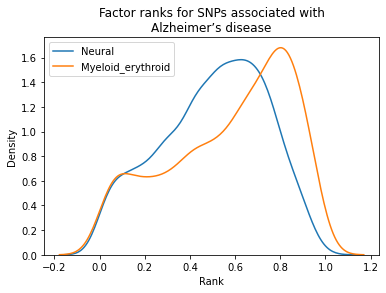

In [348]:
sns.kdeplot(phen_ranks[:, np.where(factor_order == 'Neural')[0][0]])
sns.kdeplot(phen_ranks[:, np.where(factor_order == 'Myeloid_erythroid')[0][0]])
plt.legend(['Neural', 'Myeloid_erythroid'])
plt.xlabel('Rank')
plt.title('Factor ranks for SNPs associated with\n' + phen)

What else are these SNPs involved in?

In [344]:
snps = phen_df['Reference SNP cluster ID'].to_numpy()
snps_df = gwas[gwas['Reference SNP cluster ID'].isin(snps)]
print(snps_df.shape)

(20721, 6)


In [345]:
other_phens, other_phen_counts = np.unique(snps_df['phenotype'].astype(str), return_counts=True)

In [346]:
other_phen_counts = other_phen_counts[other_phens!='nan']
other_phens = other_phens[other_phens!='nan']

other_phen_counts = other_phen_counts[other_phens!=phen]
other_phens = other_phens[other_phens!=phen]

Text(0.5, 1.0, 'Top other phenotypes for SNPs associated with\nAlzheimer’s disease')

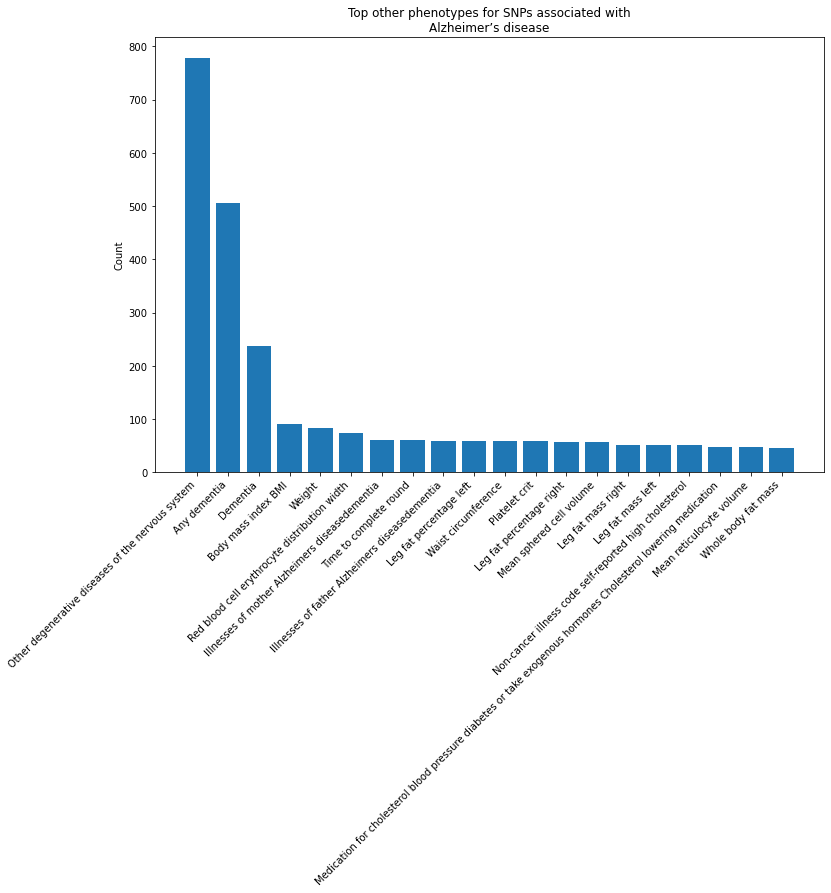

In [347]:
fig = plt.figure(figsize=(12, 8))  
fig.patch.set_facecolor('white')

plt_counts = -np.sort(-other_phen_counts)[:20]
plt_labels = other_phens[np.argsort(-other_phen_counts)][:20]

plt.bar(np.arange(len(plt_counts)), plt_counts)
plt.xticks(np.arange(len(plt_counts)), plt_labels, rotation=45, ha='right')

plt.ylabel('Count')
plt.title('Top other phenotypes for SNPs associated with\n' + phen)

**Genesets**

In [3]:
scale = '25'

# files
datadir = '/home/ctrader/region_similarity/data/rank_based/'
# gz_file_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230412.sorted.rownum4.bed.gz'
query_path = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
# sub_path = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'
tabix_url = 'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.' + scale + 'kb.regions.CT20230427.sorted.rownum4.factorranks5t38.bed.gz'

In [244]:
# search space
# ranks = np.load(sub_path)['percentiles']

# hdf5_f = h5py.File(query_path, 'r')
# ranks_full = hdf5_f['percentiles'][:]
# hdf5_f.close()

In [4]:
def target_region_sig(ranks, target_region_ranks):
    # mean and std of factor ranks in search space
    all_mean = np.mean(ranks, axis=0)
    all_std = np.std(ranks, axis=0)

    # mean of factor ranks in target regions
    target_region_mean = np.mean(target_region_ranks, axis=0)

    # Z score
    Z = (target_region_mean - all_mean) / (all_std / np.sqrt(target_region_ranks.shape[0]))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z

def tabix_query(filename, query):
    # Use subprocess with tabix and return hits
    process = Popen(['tabix', '-f', filename, query], stdout=PIPE)

    hits = []
    for line in process.stdout:
        hits.append(np.char.decode(line.strip().split()))
    hits = np.array(hits)
    return hits

# determine roi from query coordinates
def load_roi(genomic_location, link_path):

    # determine chromosome, start, and end from query
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    # retrieve possible rois
    possible_coords = tabix_query(link_path, genomic_location)

    # find closest roi
    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)
    total_dist = start_dist + end_dist
    min_dist = np.min(total_dist)
    min_dist_region_inds = np.where(total_dist == min_dist)[0]
    middle_ind = min_dist_region_inds[np.floor(len(min_dist_region_inds) / 2).astype(int)]
    query_region = possible_coords[middle_ind]

    roi = int(query_region[3])
    roi_percents = query_region[4:].astype('float32')
    roi_coords = query_region[:3]

    return roi, roi_percents, roi_coords

In [5]:
datadir = '/home/ctrader/region_similarity/data/'
hallmark_f =  datadir + 'h.all.v7.5.1.symbols.gmt'
# c1_f = datadir + 'c1.all.v7.5.1.symbols.gmt'
c2_f = datadir + 'c2.all.v7.5.1.symbols.gmt'


geneset2genes = {}
for gs_f in [hallmark_f, c2_f]:  # , c1_f
    f = open(gs_f)
    for line in f.readlines():
        line = line.strip().split('\t')
        geneset2genes[line[0]] = line[2:]
        
# hgeneset2genes = {}
# f = open(hallmark_f)
# for line in f.readlines():
#     line = line.strip().split('\t')
#     hgeneset2genes[line[0]] = line[2:]
    
# c1geneset2genes = {}
# f = open(c1_f)
# for line in f.readlines():
#     line = line.strip().split('\t')
#     c1geneset2genes[line[0]] = line[2:]
    
# c2geneset2genes = {}
# f = open(c2_f)
# for line in f.readlines():
#     line = line.strip().split('\t')
#     c2geneset2genes[line[0]] = line[2:]

In [6]:
datadir = '/home/ctrader/region_similarity/data/'
genes_f = datadir + 'gencode.v41.basic.annotation.parsed.CT20221007.txt'
f = open(genes_f)

gene2coords = {}
for line in f.readlines():
    line = line.strip().split('\t')
    if line[4] == 'gene':
        gene = line[3]
        if gene not in gene2coords:
            gene2coords[gene] = np.array([line[0] + ':' + line[6] + '-' + line[7]])  # promoter bp
        else:
            gene2coords[gene] = np.append(gene2coords[gene], np.array([line[0] + ':' + line[6] + '-' + line[7]]))
#             print(gene)

In [7]:
genes_in_genesets_l = list(geneset2genes.values())

genes_in_genesets = []
for l in genes_in_genesets_l:
    genes_in_genesets.extend(l)
genes_in_genesets, genes_in_genesets_counts = np.unique(genes_in_genesets, return_counts=True)

In [8]:
genes_in_genesets.shape, len(geneset2genes)

((21728,), 6416)

In [210]:
# genes_in_hgenesets_l = list(hgeneset2genes.values())
# genes_in_hgenesets = []
# for l in genes_in_hgenesets_l:
#     genes_in_hgenesets.extend(l)
# genes_in_hgenesets, genes_in_hgenesets_counts = np.unique(genes_in_hgenesets, return_counts=True)


# genes_in_c1genesets_l = list(c1geneset2genes.values())
# genes_in_c1genesets = []
# for l in genes_in_c1genesets_l:
#     genes_in_c1genesets.extend(l)
# genes_in_c1genesets, genes_in_c1genesets_counts = np.unique(genes_in_c1genesets, return_counts=True)


# genes_in_c2genesets_l = list(c2geneset2genes.values())
# genes_in_c2genesets = []
# for l in genes_in_c2genesets_l:
#     genes_in_c2genesets.extend(l)
# genes_in_c2genesets, genes_in_c2genesets_counts = np.unique(genes_in_c2genesets, return_counts=True)

In [214]:
# genes_in_hgenesets.shape, genes_in_c1genesets.shape, genes_in_c2genesets.shape

((4383,), (40721,), (21728,))

In [235]:
# genes_in_c1genesets[(~np.isin(genes_in_c1genesets, genes_in_hgenesets)) & 
#                     (~np.isin(genes_in_c1genesets, genes_in_c2genesets))].shape

(19018,)

In [236]:
# genes_in_c1genesets[(np.isin(genes_in_c1genesets, genes_in_hgenesets)) | 
#                     (np.isin(genes_in_c1genesets, genes_in_c2genesets))].shape

(21703,)

In [250]:
# # find background ranks (genic regions only)

# # names of all genes
# all_genes = np.array(list(gene2coords.keys()))

# # get coordinates for all genes
# all_gene_true_coords = []
# for g in all_genes:
#     if ((len(gene2coords[g]) == 1) & (gene2coords[g][0].split(':')[0][-1] != 'M')):
#         all_gene_true_coords.append(gene2coords[g][0])
# all_gene_true_coords = np.array(all_gene_true_coords)

# # ranks for all genic regions
# all_gene_roi = []
# all_gene_ranks = []
# all_gene_coords = []
# for g in all_gene_true_coords:
#     g_roi, g_roi_ranks, g_roi_coords = load_roi(g, tabix_url)
#     all_gene_roi.append(g_roi)
#     all_gene_ranks.append(g_roi_ranks)
#     all_gene_coords.append(g_roi_coords)
    
# # finding the unique regions
# gs_expected_roi, inds = np.unique(all_gene_roi, return_index=True)
# gs_expected_ranks = np.array(all_gene_ranks)[inds]
# gs_expected_coords = np.array(all_gene_coords)[inds]

# # datadir = '/home/ctrader/region_similarity/data/rank_based/'
# # out_f = datadir + 'single_coord_mapping_gene_promoter_25kb_region_ranks.gencode.v41.CT20230504.npz'
# # np.savez(out_f, indicies=gs_expected_roi, ranks=gs_expected_ranks, coordinates=gs_expected_coords)

In [251]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'single_coord_mapping_gene_promoter_25kb_region_ranks.gencode.v41.CT20230504.npz'
# gs_expected_roi = np.load(out_f)['indicies']
# gs_expected_ranks = np.load(out_f)['ranks']
# gs_expected_coords = np.load(out_f)['coordinates']

In [9]:
genes_in_genesets.shape

(21728,)

In [10]:
# # find background ranks (genic regions in at least 1 geneset only)

# # names of all genes (in at least 1 geneset)
# all_genes = genes_in_genesets

# # get coordinates for all genes
# all_gene_true_coords = []
# for g in all_genes:
#     if g in gene2coords:
#         if ((len(gene2coords[g]) == 1) & (gene2coords[g][0].split(':')[0][-1] != 'M')):
#             all_gene_true_coords.append(gene2coords[g][0])
# all_gene_true_coords = np.array(all_gene_true_coords)

# # ranks for all genic regions
# all_gene_roi = []
# all_gene_ranks = []
# all_gene_coords = []
# for g in all_gene_true_coords:
#     g_roi, g_roi_ranks, g_roi_coords = load_roi(g, tabix_url)
#     all_gene_roi.append(g_roi)
#     all_gene_ranks.append(g_roi_ranks)
#     all_gene_coords.append(g_roi_coords)
    
# # finding the unique regions
# gs_expected_roi, inds = np.unique(all_gene_roi, return_index=True)
# gs_expected_ranks = np.array(all_gene_ranks)[inds]
# gs_expected_coords = np.array(all_gene_coords)[inds]

# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'single_coord_mapping_genes_in_gs_promoter_25kb_region_ranks.gencode.v41.CT20230518.npz'
# np.savez(out_f, indices=gs_expected_roi, ranks=gs_expected_ranks, coordinates=gs_expected_coords)

In [9]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
out_f = datadir + 'single_coord_mapping_genes_in_gs_promoter_25kb_region_ranks.gencode.v41.CT20230518.npz'
gs_expected_roi = np.load(out_f)['indices']
gs_expected_ranks = np.load(out_f)['ranks']
gs_expected_coords = np.load(out_f)['coordinates']

gs_expected_ranks_mean = np.mean(gs_expected_ranks, axis=0)

In [16]:
genesets = np.array(list(geneset2genes.keys()))
genesets[np.char.find(genesets, 'CARD') != -1]

array(['CARDOSO_RESPONSE_TO_GAMMA_RADIATION_AND_3AB',
       'CARD_MIR302A_TARGETS', 'KEGG_CARDIAC_MUSCLE_CONTRACTION',
       'KEGG_HYPERTROPHIC_CARDIOMYOPATHY_HCM',
       'KEGG_ARRHYTHMOGENIC_RIGHT_VENTRICULAR_CARDIOMYOPATHY_ARVC',
       'KEGG_DILATED_CARDIOMYOPATHY', 'REACTOME_CARDIAC_CONDUCTION',
       'WP_CARDIAC_HYPERTROPHIC_RESPONSE',
       'WP_EV_RELEASE_FROM_CARDIAC_CELLS_AND_THEIR_FUNCTIONAL_EFFECTS',
       'WP_HYPOTHESIZED_PATHWAYS_IN_PATHOGENESIS_OF_CARDIOVASCULAR_DISEASE',
       'WP_ACUTE_VIRAL_MYOCARDITIS',
       'WP_MIR222_IN_EXERCISEINDUCED_CARDIAC_GROWTH',
       'WP_CARDIAC_PROGENITOR_DIFFERENTIATION',
       'WP_EXTRACELLULAR_VESICLES_IN_THE_CROSSTALK_OF_CARDIAC_CELLS',
       'WP_CALCIUM_REGULATION_IN_CARDIAC_CELLS',
       'WP_MICRORNAS_IN_CARDIOMYOCYTE_HYPERTROPHY',
       'WP_TRANSCRIPTION_FACTORS_REGULATE_MIRNAS_RELATED_TO_CARDIAC_HYPERTROPHY',
       'WP_ARRHYTHMOGENIC_RIGHT_VENTRICULAR_CARDIOMYOPATHY',
       'PETRETTO_CARDIAC_HYPERTROPHY', 'BIOCARTA_CA

In [10]:
geneset = 'MARSHALL_VIRAL_INFECTION_RESPONSE_UP'

genes = geneset2genes[geneset]

In [11]:
# for k in geneset2genes.keys():
#     if len(geneset2genes[k]) == 10:
#         print(k)

In [12]:
len(genes)

10

In [13]:
# get coordinates for genes in geneset
gs_true_coords = []
for g in genes:
    if g in gene2coords:
        coords = gene2coords[g]
        if ((len(coords) == 1) & (coords[0].split(':')[0][-1] != 'M')):
            gs_true_coords.append(coords[0])

In [14]:
len(gs_true_coords)

10

In [15]:
# get ranks
gs_rois = []
gs_ranks = []
gs_coords = []
for coord in gs_true_coords:
    roi, roi_ranks, roi_coords = load_roi(coord, tabix_url)
    gs_rois.append(roi)
    gs_ranks.append(roi_ranks)
    gs_coords.append(roi_coords)
    
# no region occurring twice
gs_rois, inds = np.unique(gs_rois, return_index=True)
gs_ranks = np.array(gs_ranks)[inds]
gs_coords = np.array(gs_coords)[inds]

In [23]:
# gs_pval, gs_z = target_region_sig(gs_expected_ranks, gs_ranks)

In [24]:
# for f, z, i in zip(factor_order[np.argsort(-gs_z)], -np.sort(-gs_z), range(1, len(gs_z)+1)):
#     print(i, f, z)

In [25]:
# for f, z, i in zip(factor_order[np.argsort(-gs_z)], -np.sort(-gs_z), range(1, len(gs_z)+1)):
#     if f in DHS_factors:
#         print(i, f, z)

Text(0.5, 1.0, 'Geneset mean rank enrichment: MARSHALL_VIRAL_INFECTION_RESPONSE_UP')

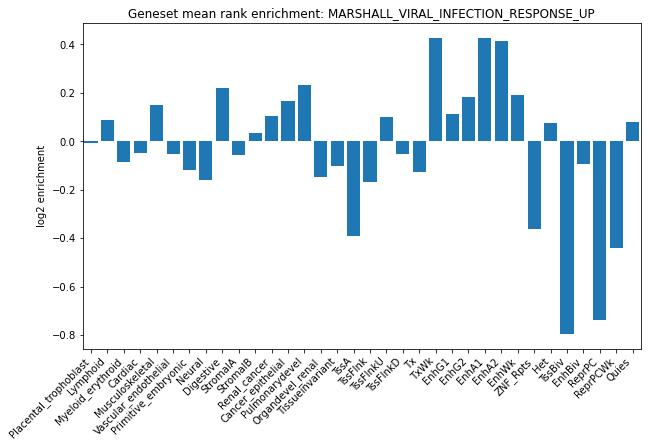

In [16]:
obs = np.mean(gs_ranks, axis=0)
exp = np.mean(gs_expected_ranks, axis=0)

ooe = obs / exp
log2ooe = np.log2(ooe)


fig = plt.figure(figsize=(10, 6))  
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(log2ooe)), log2ooe)

plt.xticks(np.arange(len(log2ooe)), factor_order, rotation=45, ha='right')
plt.xlim([-0.5, len(log2ooe)-0.5])

plt.ylabel('log2 enrichment')
plt.title('Geneset mean rank enrichment: %s' %geneset)


All geneset analysis

In [3]:
def geneset2ranks(geneset):
    tabix_url = 'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.25kb.regions.CT20230427.sorted.rownum4.factorranks5t38.bed.gz'
    
    genes = geneset2genes[geneset]
    
    gs_true_coords = []
    for g in genes:
        if g in gene2coords:
            coords = gene2coords[g]
            if ((len(coords) == 1) & (coords[0].split(':')[0][-1] != 'M')):
                gs_true_coords.append(coords[0])
            else:
                print('Error: Gene %s has multiple coordinates or is on chrM' %g)
        else:
            print('Error: Coordinates for gene %s not found' %g)
    
    # get ranks
    gs_rois_pre = []
    gs_ranks_pre = []
    gs_coords_pre = []
    for coord in gs_true_coords:
        roi, roi_ranks, roi_coords = load_roi(coord, tabix_url)
        gs_rois_pre.append(roi)
        gs_ranks_pre.append(roi_ranks)
        gs_coords_pre.append(roi_coords)

    # no region occurring twice
    gs_rois, inds = np.unique(gs_rois_pre, return_index=True)
    gs_ranks = np.array(gs_ranks_pre)[inds]
    gs_coords = np.array(gs_coords_pre)[inds]
    
    gs_coords_return = []
    for coord in gs_coords:
        gs_coords_return.append(coord[0] + ':' + coord[1] + '-' + coord[2])
    
    return gs_rois, gs_ranks, gs_coords_return

def gene2ranks(g):
    coord = ''
    if g in gene2coords:
        coords = gene2coords[g]
        if ((len(coords) == 1) & (coords[0].split(':')[0][-1] != 'M')):
            coord = coords[0]
        else:
            print('Error: Gene %s has multiple coordinates or is on chrM' %g)
    else:
        print('Error: Coordinates for gene %s not found' %g)
    
    if coord:
        roi, roi_ranks, roi_coords = load_roi(coord, tabix_url)
        roi_coords_return = roi_coords[0] + ':' + roi_coords[1] + '-' + roi_coords[2]
    
    else:
        roi = roi_ranks = roi_coords = None
        
    return roi, roi_ranks, roi_coords

In [34]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/indexed/'
# scale = '25'
# local_tabix_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230427.sorted.rownum4.factorranks5t38.bed.gz'

In [35]:
# geneset_tracker = []
# enrichment_tracker = []

# for geneset in list(geneset2genes.keys())[2915:2916]:
#     print(geneset)
#     t = time.time()
#     geneset_tracker.append(geneset)
#     genes = geneset2genes[geneset]

#     # get coordinates for genes in geneset
#     gs_true_coords = []
#     for g in genes:
#         if g in gene2coords:
#             coords = gene2coords[g]
#             if ((len(coords) == 1) & (coords[0].split(':')[0][-1] != 'M')):
#                 gs_true_coords.append(coords[0])

#     # get ranks
#     gs_rois = []
#     gs_ranks = []
#     gs_coords = []
#     for coord in gs_true_coords:
#         roi, roi_ranks, roi_coords = load_roi(coord, local_tabix_path)
#         gs_rois.append(roi)
#         gs_ranks.append(roi_ranks)
#         gs_coords.append(roi_coords)

#     # no region occurring twice
#     gs_rois, inds = np.unique(gs_rois, return_index=True)
#     gs_ranks = np.array(gs_ranks)[inds]
#     gs_coords = np.array(gs_coords)[inds]

#     # get obs/exp
#     obs = np.mean(gs_ranks, axis=0)
#     exp = np.mean(gs_expected_ranks, axis=0)

#     ooe = obs / exp
#     log2ooe = np.log2(ooe)
#     enrichment_tracker.append(log2ooe)
#     print(time.time()-t)

REACTOME_REGULATION_OF_GENE_EXPRESSION_IN_ENDOCRINE_COMMITTED_NEUROG3_PROGENITOR_CELLS
1.4369745254516602


/tmp/ipykernel_11690/3360375751.py:38: RuntimeWarning: divide by zero encountered in log2
  log2ooe = np.log2(ooe)


In [38]:
# geneset_tracker = np.array(geneset_tracker)
# enrichment_tracker = np.array(enrichment_tracker)

In [39]:
# enrichment_tracker.shape

(3, 34)

In [ ]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# outf = datadir + 'all_geneset_25kb_regional_enrichment_analysis_CT20230510.npz'
# np.savez(outf, enrichments=enrichment_tracker, genesets=geneset_tracker, factor_order=factor_order)

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
savedf = datadir + 'all_geneset_25kb_regional_enrichment_analysis_CT20230518.npz'

enrichments = np.load(savedf)['enrichments']
genesets = np.load(savedf)['genesets']
factor_order = np.load(savedf)['factor_order']

min_noninf = np.nanmin(enrichments[~np.isinf(enrichments)])
enrichments = np.where(np.isinf(enrichments), min_noninf, enrichments)
enrichments = np.where(np.isnan(enrichments), 0, enrichments)  # only with c1

In [243]:
geneset = 'REACTOME_ERYTHROPOIETIN_ACTIVATES_STAT5'
example_gs_genes = geneset2genes[geneset]
example_gs_gene_counts = []
example_gs_ngte_counts = []

for gene in example_gs_genes:
    gene_ind = np.where(genes_in_genesets == gene)[0][0]
    c = genes_in_genesets_counts[gene_ind]
    print(gene + ' Count: ' + str(c))
    example_gs_gene_counts.append(c)
    
    gene_roi, gene_ranks, gene_coords = gene2ranks(gene)
    if gene_roi != None:
        num_ranks_greater_than_expected = np.count_nonzero(gene_ranks > gs_expected_ranks_mean)
        print('Number of %s Factor Ranks > GS expected: %s/34\n' %(
            gene, num_ranks_greater_than_expected)
        )
        example_gs_ngte_counts.append(num_ranks_greater_than_expected)
    
print('\nAverage Gene Count: ' + str(np.mean(example_gs_gene_counts)))
print('Average Number of Factor Ranks > GS expected: ' + str(np.mean(example_gs_ngte_counts)))

JAK2 Count: 175
Number of JAK2 Factor Ranks > GS expected: 32/34

STAT5A Count: 156
Number of STAT5A Factor Ranks > GS expected: 30/34

EPO Count: 41
Number of EPO Factor Ranks > GS expected: 29/34

STAT5B Count: 132
Number of STAT5B Factor Ranks > GS expected: 30/34

IRS2 Count: 112
Number of IRS2 Factor Ranks > GS expected: 32/34

EPOR Count: 60
Number of EPOR Factor Ranks > GS expected: 32/34

LYN Count: 174
Number of LYN Factor Ranks > GS expected: 29/34


Average Gene Count: 121.42857142857143
Average Number of Factor Ranks > GS expected: 30.571428571428573


Text(0.5, 1.0, 'Geneset mean rank enrichment: HALLMARK_MYOGENESIS')

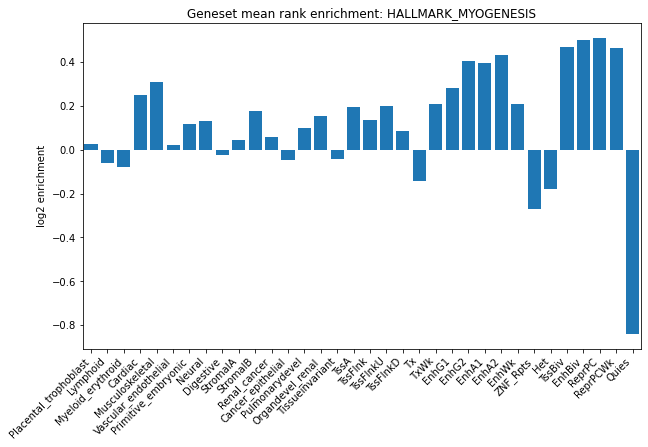

In [19]:
geneset = 'HALLMARK_MYOGENESIS'

fig = plt.figure(figsize=(10, 6))  
fig.patch.set_facecolor('white')

ind = np.where(genesets==geneset)[0][0]

plt.bar(np.arange(len(enrichments[ind])), enrichments[ind])

plt.xticks(np.arange(len(enrichments[ind])), factor_order, rotation=45, ha='right')
plt.xlim([-0.5, len(enrichments[ind])-0.5])

plt.ylabel('log2 enrichment')
plt.title('Geneset mean rank enrichment: %s' %geneset)

In [20]:
# for all genesets (ordered by enrichment sum), get the average count of all its genes in all other genesets
enrichment_sums = np.sum(enrichments, axis=1)
enrichment_sums_sorted = np.sort(enrichment_sums)
average_gene_counts = []
average_num_factor_ranks_gte = []

for i in np.argsort(enrichment_sums):
    gs = genesets[i]
    genes = geneset2genes[gs]
    gs_counts = []
    for g in genes:
        g_ind = np.where(genes_in_genesets == g)[0][0]
        c = genes_in_genesets_counts[g_ind]
        gs_counts.append(c)
    gs_counts_mean = np.mean(gs_counts)
    average_gene_counts.append(gs_counts_mean)
    
average_gene_counts = np.array(average_gene_counts)

Text(0, 0.5, 'Average Number of Genesets Genes Belong to')

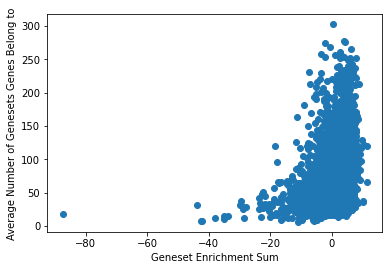

In [21]:
plt.scatter(enrichment_sums_sorted, average_gene_counts)
plt.xlabel('Geneset Enrichment Sum')
plt.ylabel('Average Number of Genesets Genes Belong to')

All geneset analysis

Text(0.5, 0.94, 'All geneset enrichments by factor')

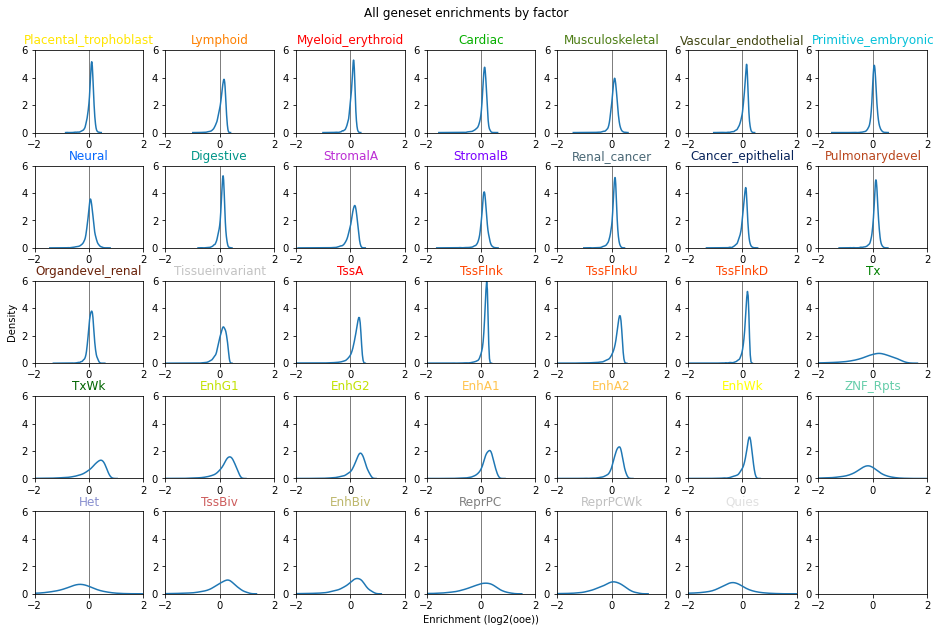

In [23]:
fig, axes = plt.subplots(5, 7, figsize=(16, 10))  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0.4)
max_y = 6
max_x = 2
min_x = -2

axes.ravel()

for i in range(34):
    axisx = i // 7
    axisy = i % 7
    ax = axes[axisx, axisy]
    ax.plot([0, 0], [0, max_y], c='k', linewidth=0.5)
    sns.kdeplot(enrichments[:, i], ax=ax)
    ax.set_title(factor_order[i], c=color_order[i])
    ax.set_xlim([min_x, max_x])
    ax.set_ylim([0, max_y])
    if ((axisx != 2) | (axisy != 0)):
        ax.set_ylabel('')
    if ((axisx == 4) & (axisy == 3)):
        ax.set_xlabel('Enrichment (log2(ooe))')
    
# leftover
axes[-1, -1].set_xlim([min_x, max_x])
axes[-1, -1].set_ylim([0, max_y])

fig.suptitle('All geneset enrichments by factor', y=0.94)

Clustering genesets

In [5]:
clustering_method='cosine'

# gs_enrich_cos = pdist(np.where(enrichments == 0, min_noninf, enrichments), metric='cosine')
gs_enrich_cos = pdist(enrichments, metric=clustering_method)
z_cluster = hierarchy.average(gs_enrich_cos)
z_cluster_opt = hierarchy.optimal_leaf_ordering(z_cluster, gs_enrich_cos)

In [6]:
# leaves = hierarchy.leaves_list(z_cluster)
leaves = hierarchy.leaves_list(z_cluster_opt)
genesets_ordered = genesets[leaves]

In [154]:
# fig = plt.figure(figsize=(12, 15))  
# fig.patch.set_facecolor('white')

# # have to flip leaves to match dendrogram
# sns.heatmap(enrichments[np.flip(leaves)], cmap='RdBu', center=0, vmax=np.max(enrichments), vmin=np.min(enrichments))
# plt.xticks(np.arange(len(factor_order)) + 0.5, factor_order, rotation=90)
# plt.title('')

In [155]:
ind = np.where(genesets_ordered == 'REACTOME_ADAPTIVE_IMMUNE_SYSTEM')[0][0]
leaves_of_interest = leaves[ind - 1: ind + 2]
print(genesets_ordered[ind - 1: ind + 2])
print(leaves_of_interest)
print(enrichments[leaves_of_interest])

['WP_CYTOSOLIC_DNASENSING_PATHWAY' 'REACTOME_ADAPTIVE_IMMUNE_SYSTEM'
 'REACTOME_INNATE_IMMUNE_SYSTEM']
[4281 2270 2421]
[[ 0.07980832  0.18559353  0.17056005 -0.03020361 -0.00188478  0.15059207
  -0.03997871 -0.19754417 -0.03440989  0.07764243  0.06932847  0.05297991
   0.11263358 -0.02701758 -0.13537772  0.04142688  0.10584842  0.01985046
   0.13534278  0.04909124  0.33313486  0.19290937  0.28995007  0.22121006
   0.04311809  0.00115457  0.18371019 -0.07815553 -0.2932416  -0.24499571
  -0.03298972 -0.21378383 -0.10743449 -0.02801896]
 [ 0.03581632  0.15397933  0.11254228 -0.02259281 -0.01988422  0.06250076
  -0.03718226 -0.12564333  0.0010152   0.00582069 -0.01532235  0.02230838
   0.01467486 -0.04910216 -0.05402713  0.04872333  0.12650268  0.07623448
   0.15336385  0.08054464  0.2109473   0.16093391  0.22700259  0.21378936
   0.14166157  0.07164861  0.15001854 -0.04718971 -0.11174671 -0.1542592
  -0.06440733 -0.1418024  -0.07514393 -0.15545684]
 [ 0.06672975  0.10898619  0.10765545 -

In [156]:
# fig = plt.figure(figsize=(8, 15))  
# fig.patch.set_facecolor('white')
# d = hierarchy.dendrogram(z_cluster, no_labels=True, color_threshold=0, orientation='left')
# plt.title('All genesets, cosine distance, average clustering')

In [157]:
# test

# x = np.array([[1, 1], [1, 1], [2, 3], [2, 3], [-2, 2], [1, 1], [1, 1]])
# x_cos = pdist(x, metric='euclidean')
# x_cluster = hierarchy.average(x_cos)
# x_leaves = hierarchy.leaves_list(x_cluster)
# print(x_leaves)
# print(np.flip(x_leaves))

# fig, axes = plt.subplots(1, 2, figsize=(4, 8), gridspec_kw={'width_ratios': [1, 1]})  
# fig.patch.set_facecolor('white')
# plt.subplots_adjust(wspace=0)


# axes.ravel()
# d = hierarchy.dendrogram(x_cluster, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')
# axes[0].set_xticks([])

# sns.heatmap(x[np.flip(x_leaves)], ax=axes[1], cmap='RdBu', center=0, vmax=np.max(enrichments), vmin=np.min(enrichments))
# axes[1].set_yticks([])

In [164]:
np.min(enrichments[:, :16])

-1.981765

In [168]:
np.mean(gs_expected_ranks, axis=0)

array([0.670169  , 0.7697477 , 0.7372702 , 0.68281   , 0.6175725 ,
       0.69378656, 0.6890887 , 0.5927384 , 0.7139154 , 0.65463907,
       0.5965503 , 0.6469826 , 0.60787016, 0.6232294 , 0.6822172 ,
       0.7589663 , 0.7391672 , 0.7940848 , 0.7380363 , 0.8064296 ,
       0.4108795 , 0.5541599 , 0.58081096, 0.5740116 , 0.58727163,
       0.6161679 , 0.67441887, 0.27313483, 0.2016261 , 0.48162314,
       0.54208255, 0.4485912 , 0.47432947, 0.20282863], dtype=float32)

Text(0.5, 0.9, 'Hallmark and C2 geneset enrichments clustered, cosine, average, optimally ordered')

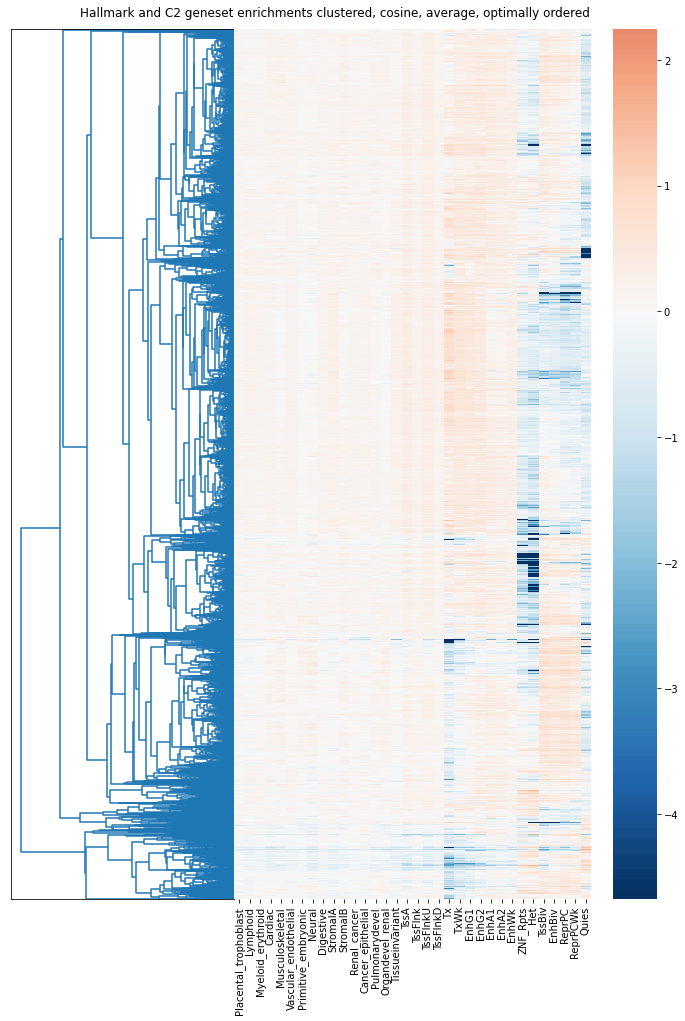

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(z_cluster_opt, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')
axes[0].set_xticks([])

# have to flip leaves to match dendrogram
sns.heatmap(enrichments[np.flip(leaves)], ax=axes[1], cmap='RdBu_r', center=0, vmax=np.max(enrichments), vmin=np.min(enrichments))
axes[1].set_yticks([])
axes[1].set_xticklabels(factor_order, rotation=90)

fig.suptitle('Hallmark and C2 geneset enrichments clustered, %s, average, optimally ordered' %clustering_method, y=0.9)

Rescaling before clustering

In [4]:
enrichments_gt0 = np.where(enrichments > 0, enrichments, 0)
enrichments_gt0_norm = enrichments_gt0 / np.max(enrichments_gt0, axis=0)

enrichments_lt0 = np.where(enrichments < 0, enrichments, 0)
enrichments_lt0_norm = enrichments_lt0 / np.abs(np.min(enrichments_lt0, axis=0))

enrichments_norm = enrichments_gt0_norm + enrichments_lt0_norm

Text(0.5, 0.9, 'Hallmark and C2 geneset enrichments clustered, cosine, average, optimally ordered (normalized enrichment heatmap)')

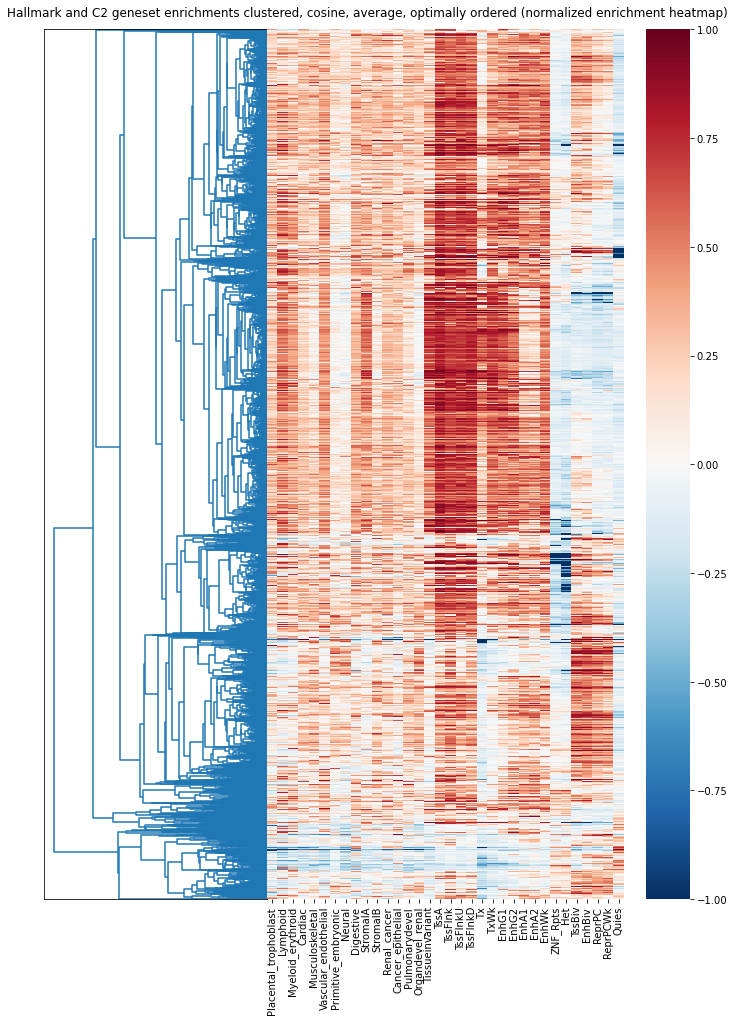

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(z_cluster_opt, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')
axes[0].set_xticks([])

# have to flip leaves to match dendrogram
sns.heatmap(enrichments_norm[np.flip(leaves)], ax=axes[1], cmap='RdBu_r', center=0, vmax=np.max(enrichments_norm), vmin=np.min(enrichments_norm))
axes[1].set_yticks([])
axes[1].set_xticklabels(factor_order, rotation=90)

fig.suptitle('Hallmark and C2 geneset enrichments clustered, %s, average, optimally ordered (normalized enrichment heatmap)' %clustering_method, y=0.9)

In [5]:
clustering_method='cosine'

gs_enrich_cos_norm = pdist(enrichments_norm, metric=clustering_method)
z_cluster_norm = hierarchy.average(gs_enrich_cos_norm)
z_cluster_norm_opt = hierarchy.optimal_leaf_ordering(z_cluster_norm, gs_enrich_cos_norm)

# leaves_norm = hierarchy.leaves_list(z_cluster_norm)
leaves_norm = hierarchy.leaves_list(z_cluster_norm_opt)
genesets_ordered_norm = genesets[leaves_norm]


Text(0.5, 0.9, 'Hallmark and C2 geneset normalized enrichments clustered, cosine, average, optimally ordered')

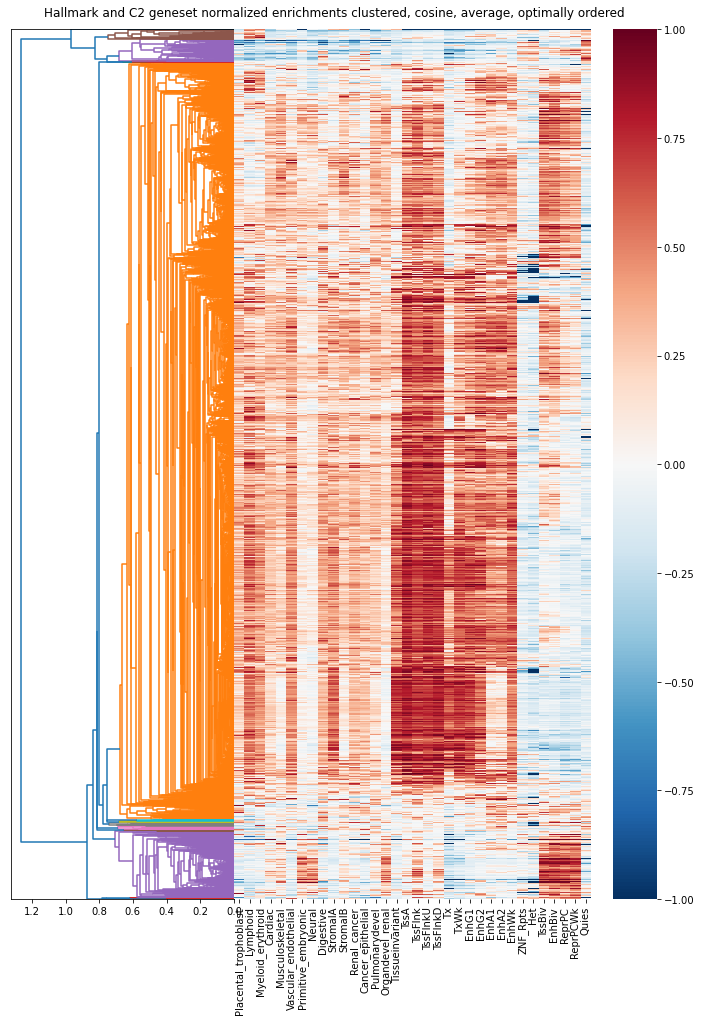

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(z_cluster_norm_opt, ax=axes[0], no_labels=True, color_threshold=0.75, orientation='left')
# axes[0].set_xticks([])

# have to flip leaves to match dendrogram
sns.heatmap(enrichments_norm[np.flip(leaves_norm)], ax=axes[1], cmap='RdBu_r', center=0, vmax=np.max(enrichments_norm), vmin=np.min(enrichments_norm))
axes[1].set_yticks([])
axes[1].set_xticklabels(factor_order, rotation=90)

fig.suptitle('Hallmark and C2 geneset normalized enrichments clustered, %s, average, optimally ordered' %clustering_method, y=0.9)

In [15]:
leaves_color_list = d['leaves_color_list']
dendrogram_leaves = d['leaves']

current_color = 'C1'

k_clusters = []
current_cluster = []

k_ind_clusters = []
current_i_cluster = []
for c, gs, i in zip(leaves_color_list, genesets_ordered_norm, dendrogram_leaves):
    if c != current_color:
        k_clusters.append(current_cluster)
        k_ind_clusters.append(current_i_cluster)
        current_cluster = []
        current_i_cluster = []
        current_color = c
    current_cluster.append(gs)
    current_i_cluster.append(i)
k_clusters.append(current_cluster)
k_ind_clusters.append(current_i_cluster)

In [16]:
k_ind_clusters

[[3423, 1827],
 [3331, 4989],
 [5604, 1104, 343, 3492, 4317, 3479, 3493, 3490],
 [794,
  222,
  1511,
  46,
  2042,
  247,
  1460,
  3714,
  3723,
  1474,
  290,
  2657,
  4992,
  4991,
  2718,
  2406,
  1530,
  610,
  3833,
  522,
  1411,
  1669,
  1532,
  1322,
  1102,
  70,
  3967,
  4167,
  5812,
  1181,
  942,
  4214,
  1485,
  1224,
  1525,
  2075,
  1524,
  2852,
  482,
  1897,
  1398,
  475,
  777,
  468,
  3995,
  3253,
  2099,
  2547,
  3890,
  466,
  3377,
  3401,
  447,
  1285,
  2901,
  3199,
  3201,
  2081,
  1919,
  366,
  1618,
  2885,
  2884,
  2827,
  2725,
  2916,
  2610,
  2219,
  1864,
  2127,
  1237,
  5226,
  3731,
  2609,
  3816,
  3814,
  3812,
  1920,
  3810,
  2906,
  4099,
  2798,
  2791,
  3032,
  1952,
  743,
  5722,
  6140,
  2799,
  1800,
  4208,
  2966,
  4219,
  2299,
  5514,
  4519,
  4544,
  3796,
  2941,
  2911,
  4168,
  2854,
  4218,
  5666,
  5723,
  4030,
  5123,
  5721,
  1671,
  5634,
  5185,
  5493,
  5492,
  5491,
  3939,
  5792,
  3825,
  2

In [10]:
k_clusters

[['REACTOME_WAX_AND_PLASMALOGEN_BIOSYNTHESIS', 'KIM_GLIS2_TARGETS_DN'],
 ['REACTOME_UREA_CYCLE', 'VETTER_TARGETS_OF_PRKCA_AND_ETS1_DN'],
 ['SOUCEK_MYC_TARGETS',
  'CHEN_ETV5_TARGETS_SERTOLI',
  'GAUSSMANN_MLL_AF4_FUSION_TARGETS_F_DN',
  'REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_INTERLEUKIN_SIGNALING',
  'WP_SULINDAC_METABOLIC_PATHWAY',
  'REACTOME_RUNX1_REGULATES_ESTROGEN_RECEPTOR_MEDIATED_TRANSCRIPTION',
  'REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_WNT_SIGNALING',
  'REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_BCR_SIGNALING'],
 ['NIKOLSKY_BREAST_CANCER_19Q13.4_AMPLICON',
  'PEPPER_CHRONIC_LYMPHOCYTIC_LEUKEMIA_UP',
  'HOFMANN_MYELODYSPLASTIC_SYNDROM_HIGH_RISK_DN',
  'HALLMARK_SPERMATOGENESIS',
  'XIE_ST_HSC_S1PR3_OE_DN',
  'TONKS_TARGETS_OF_RUNX1_RUNX1T1_FUSION_SUSTAINED_IN_MONOCYTE_DN',
  'VILIMAS_NOTCH1_TARGETS_DN',
  'REACTOME_LEISHMANIA_INFECTION',
  'REACTOME_ANTI_INFLAMMATORY_RESPONSE_FAVOURING_LEISHMANIA_PARASITE_INFECTION',
 

In [40]:
# top genesets by enrichment for each k
for k, i in zip(k_clusters, k_ind_clusters):
    i_enrichment_sums = np.sum(enrichments_norm[i], axis=1)
    top_i = np.argmax(i_enrichment_sums)
    
    print(k[top_i], i_enrichment_sums[top_i], top_i)

REACTOME_WAX_AND_PLASMALOGEN_BIOSYNTHESIS -0.37172058 0
VETTER_TARGETS_OF_PRKCA_AND_ETS1_DN 3.048467 1
REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_BCR_SIGNALING 5.628086 7
REACTOME_LIGAND_RECEPTOR_INTERACTIONS 9.226874 203
REACTOME_LIPID_PARTICLE_ORGANIZATION 3.6961966 0
SCHAEFFER_PROSTATE_DEVELOPMENT_AND_CANCER_BOX6_UP 4.332356 14
TURJANSKI_MAPK7_TARGETS 6.4679294 11
REACTOME_RSK_ACTIVATION 3.6288025 4
REACTOME_DOPAMINE_CLEARANCE_FROM_THE_SYNAPTIC_CLEFT 7.1565723 0
REACTOME_SULFIDE_OXIDATION_TO_SULFATE 18.692656 2616
NIKOLSKY_BREAST_CANCER_19Q13.1_AMPLICON 4.192298 0
GHO_ATF5_TARGETS_UP 0.48360497 9
SHIRAISHI_PLZF_TARGETS_DN 3.0595021 89
BIOCARTA_LYM_PATHWAY 4.153068 19
RUNNE_GENDER_EFFECT_UP -19.150202 0


In [13]:
# pull out names by every xth gs
for i in range(len(genesets_ordered_norm)):
    name = genesets_ordered_norm[i]
    if i % 10 == 0:
        print(name)

REACTOME_WAX_AND_PLASMALOGEN_BIOSYNTHESIS
REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_WNT_SIGNALING
REACTOME_ANTI_INFLAMMATORY_RESPONSE_FAVOURING_LEISHMANIA_PARASITE_INFECTION
WP_METHIONINE_METABOLISM_LEADING_TO_SULFUR_AMINO_ACIDS_AND_RELATED_DISORDERS
WANG_THOC1_TARGETS_UP
MYLLYKANGAS_AMPLIFICATION_HOT_SPOT_13
WP_HYPOTHETICAL_CRANIOFACIAL_DEVELOPMENT_PATHWAY
KINNEY_DNMT1_METHYLATION_TARGETS
RAFFEL_VEGFA_TARGETS_DN
NABA_ECM_AFFILIATED
REACTOME_AMINE_LIGAND_BINDING_RECEPTORS
REACTOME_REGULATION_OF_COMMISSURAL_AXON_PATHFINDING_BY_SLIT_AND_ROBO
KORKOLA_EMBRYONIC_CARCINOMA_VS_SEMINOMA_DN
REACTOME_ACTIVATION_OF_TRKA_RECEPTORS
REACTOME_PHYSIOLOGICAL_FACTORS
KEGG_MATURITY_ONSET_DIABETES_OF_THE_YOUNG
RIZ_ERYTHROID_DIFFERENTIATION_6HR
MCCOLLUM_GELDANAMYCIN_RESISTANCE_DN
WP_SEROTONIN_AND_ANXIETYRELATED_EVENTS
REACTOME_NOREPINEPHRINE_NEUROTRANSMITTER_RELEASE_CYCLE
WP_MAJOR_RECEPTORS_TARGETED_BY_EPINEPHRINE_AND_NOREPINEPHRINE
KOHOUTEK_CCNT2_TARGETS
REACTOME_LGI_ADAM_INTERACTIONS
RE

In [14]:
ind = np.where(genesets_ordered_norm == 'REACTOME_ADAPTIVE_IMMUNE_SYSTEM')[0][0]
leaves_of_interest_norm = leaves_norm[ind - 2: ind + 3]
print(genesets_ordered_norm[ind - 2: ind + 3])
print(leaves_of_interest_norm)
print(enrichments_norm[leaves_of_interest_norm])

['REACTOME_INNATE_IMMUNE_SYSTEM' 'MATTIOLI_MGUS_VS_PCL'
 'REACTOME_ADAPTIVE_IMMUNE_SYSTEM' 'HAHTOLA_SEZARY_SYNDROM_UP'
 'REACTOME_ROS_AND_RNS_PRODUCTION_IN_PHAGOCYTES']
[2421 5045 2270  289 2246]
[[ 0.16965336  0.33001485  0.32702875 -0.03483141 -0.0242685   0.06910535
  -0.02193223 -0.10801972  0.01945696 -0.00540248 -0.01734737  0.08018683
   0.07730486 -0.03114306 -0.0565568  -0.00325781  0.05355039  0.02712865
   0.15139851  0.05823278  0.11446337  0.11195154  0.19540563  0.25124723
   0.17883855  0.11887875  0.20973313  0.00677649 -0.00951675 -0.03277516
   0.01294965 -0.02766991 -0.01454546 -0.01841716]
 [ 0.15252246  0.58540374  0.4552189  -0.04470809 -0.07830939  0.14392097
  -0.01424461 -0.10829899  0.07546075  0.01934715 -0.0728287   0.10506205
  -0.00620735 -0.07441496 -0.10987124  0.16938521  0.17727269  0.12681158
   0.3327398   0.2762621   0.27742028  0.1878437   0.31669253  0.48457932
   0.12315421  0.03737325  0.21570092 -0.04521606  0.00404593 -0.08157153
  -0.0478376 

Random regions

In [95]:
# average number of genes per gs
numgenes_l = []
for geneset in geneset2genes.keys():
    numgenes = len(geneset2genes[geneset])
    numgenes_l.append(numgenes)
numgenes_per_gs = int(np.round(np.mean(numgenes_l)))

In [99]:
rand_inds = np.random.randint(0, gs_expected_ranks.shape[0], numgenes_per_gs)

# random_pval, random_z = target_region_sig(gs_expected_ranks, gs_expected_ranks[rand_inds])

In [92]:
# for f, z, i in zip(factor_order[np.argsort(-random_z)], -np.sort(-random_z), range(1, len(random_z)+1)):
#     print(i, f, z)

In [93]:
# for f, z, i in zip(factor_order[np.argsort(-random_z)], -np.sort(-random_z), range(1, len(random_z)+1)):
#     if f in DHS_factors:
#         print(i, f, z)

Text(0.5, 1.0, 'Geneset mean rank enrichment: Random')

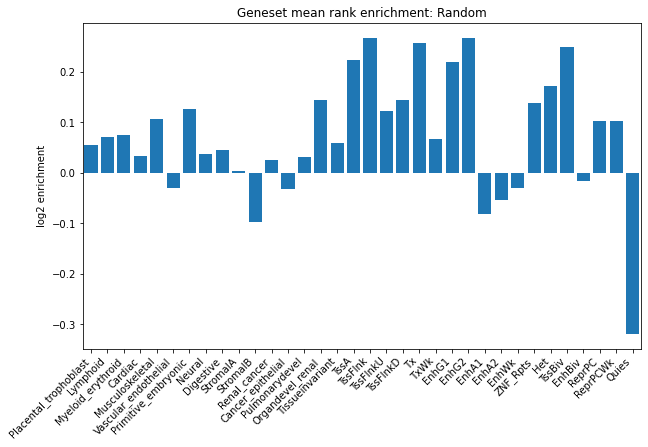

In [100]:
obs = np.mean(gs_expected_ranks[rand_inds], axis=0)
exp = np.mean(gs_expected_ranks, axis=0)

ooe = obs / exp
log2ooe = np.log2(ooe)


fig = plt.figure(figsize=(10, 6))  
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(log2ooe)), log2ooe)

plt.xticks(np.arange(len(log2ooe)), factor_order, rotation=45, ha='right')
plt.xlim([-0.5, len(log2ooe)-0.5])

plt.ylabel('log2 enrichment')
plt.title('Geneset mean rank enrichment: Random')


**Plotting Mean Ranks for Search Spaces**

Text(0.5, 0.92, 'Average factor ranks for per factor scaling approach')

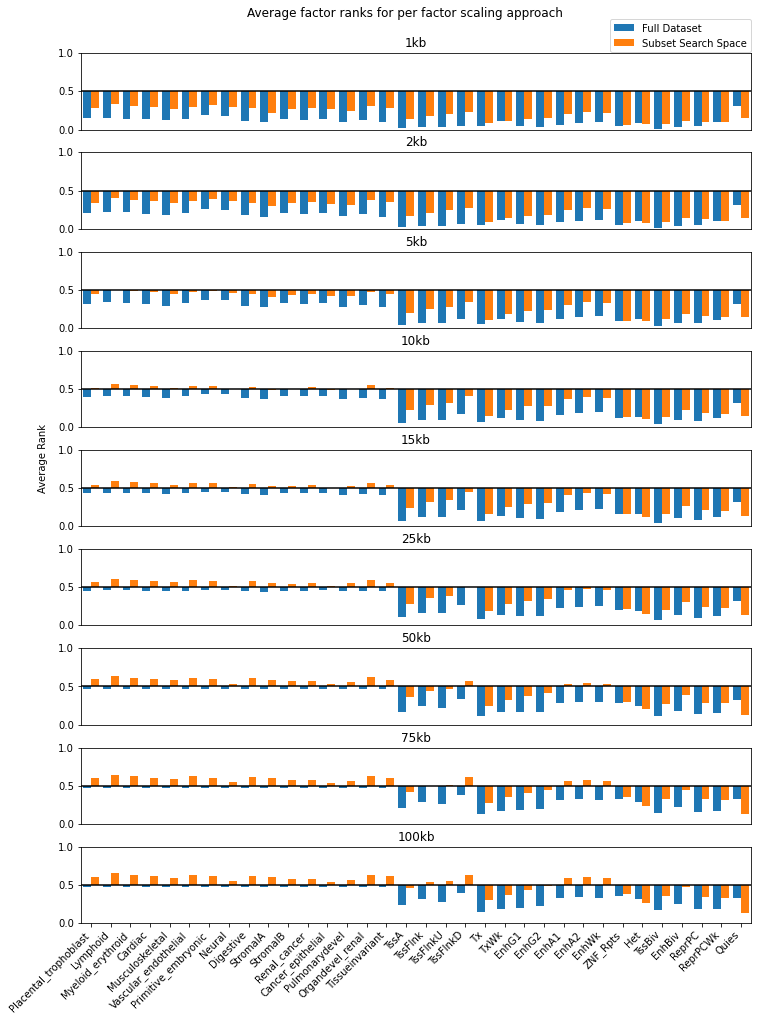

In [4]:
scales = ['1', '2', '5', '10', '15', '25', '50', '75', '100']

fig, axes = plt.subplots(len(scales), 1, figsize=(12, 16))  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0.3)

axes.ravel()

for ax, scale in zip(axes, scales):
    
    # load data
    # files
    datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
    query_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
    sub_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

    # search space
    ranks = np.load(sub_path)['percentiles']

    # full ranks
    hdf5_f = h5py.File(query_path, 'r')
    ranks_full = hdf5_f['percentiles'][:]
    hdf5_f.close()
    
    ranks_mean = np.mean(ranks, axis=0)
    ranks_full_mean = np.mean(ranks_full, axis=0)
    
    ranks_mean_plt = ranks_mean * 2 - 1
    ranks_full_mean_plt = ranks_full_mean * 2 - 1
    
    ax.bar(np.arange(len(ranks_full_mean_plt)) - 0.2, ranks_full_mean_plt, width=0.4)
    ax.bar(np.arange(len(ranks_mean_plt)) + 0.2, ranks_mean_plt, width=0.4)
    
    
    if scale == '1':
        ax.legend(['Full Dataset', 'Subset Search Space'], loc=(0.79, 1.01))
    
    ax.plot([-0.5, len(ranks_full_mean_plt) - 0.2], [0, 0], c='k')
    ax.set_ylim([-1, 1])
    ax.set_xlim([-0.5, len(ranks_full_mean_plt) - 0.5])
    
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(['0.0', '0.5', '1.0'])
    
    ax.set_xticks([])
    ax.set_title(scale + 'kb')
    
axes[-1].set_xticks(np.arange(len(ranks_full_mean_plt)))
axes[-1].set_xticklabels(factor_order, rotation=45, ha='right')

fig.text(0.075, 0.5, 'Average Rank', rotation=90)



fig.suptitle('Average factor ranks for per factor scaling approach', y=0.92)

Text(0.5, 0.92, 'Average factor ranks for constant scaling approach')

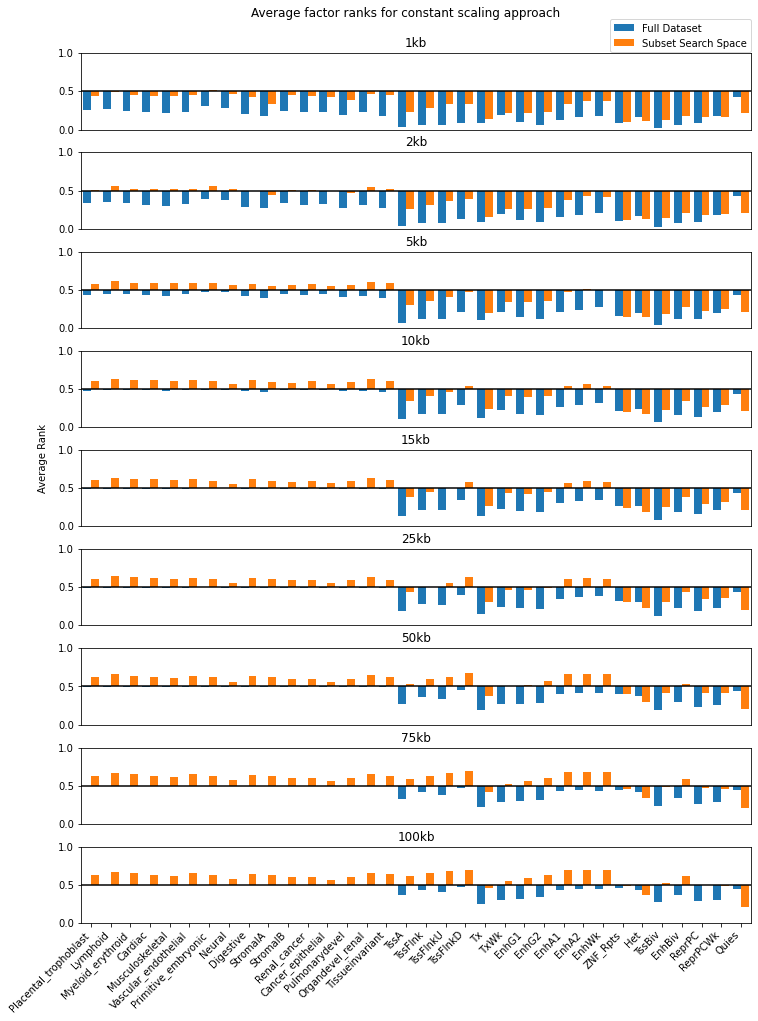

In [5]:
scales = ['1', '2', '5', '10', '15', '25', '50', '75', '100']

fig, axes = plt.subplots(len(scales), 1, figsize=(12, 16))  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0.3)

axes.ravel()

for ax, scale in zip(axes, scales):
    
    # load data
    # files
    datadir = '/home/ctrader/region_similarity/data/rank_based/'
    query_path = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
    sub_path = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

    # search space
    ranks = np.load(sub_path)['percentiles']

    # full ranks
    hdf5_f = h5py.File(query_path, 'r')
    ranks_full = hdf5_f['percentiles'][:]
    hdf5_f.close()
    
    ranks_mean = np.mean(ranks, axis=0)
    ranks_full_mean = np.mean(ranks_full, axis=0)
    
    ranks_mean_plt = ranks_mean * 2 - 1
    ranks_full_mean_plt = ranks_full_mean * 2 - 1
    
    ax.bar(np.arange(len(ranks_full_mean_plt)) - 0.2, ranks_full_mean_plt, width=0.4)
    ax.bar(np.arange(len(ranks_mean_plt)) + 0.2, ranks_mean_plt, width=0.4)
    
    
    if scale == '1':
        ax.legend(['Full Dataset', 'Subset Search Space'], loc=(0.79, 1.01))
    
    ax.plot([-0.5, len(ranks_full_mean_plt) - 0.2], [0, 0], c='k')
    ax.set_ylim([-1, 1])
    ax.set_xlim([-0.5, len(ranks_full_mean_plt) - 0.5])
    
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(['0.0', '0.5', '1.0'])
    
    ax.set_xticks([])
    ax.set_title(scale + 'kb')
    
axes[-1].set_xticks(np.arange(len(ranks_full_mean_plt)))
axes[-1].set_xticklabels(factor_order, rotation=45, ha='right')

fig.text(0.075, 0.5, 'Average Rank', rotation=90)



fig.suptitle('Average factor ranks for constant scaling approach', y=0.92)

In [54]:
scale = '100'
query_path = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

# full ranks
hdf5_f = h5py.File(query_path, 'r')
ranks_full = hdf5_f['percentiles'][:]
hdf5_f.close()

ranks_full.shape

(3088281, 34)

**Testing out Ranking mechanisms**

In [411]:
np.random.random((10, 4))


array([[0.94685741, 0.65202811, 0.20797311, 0.26532206],
       [0.03172097, 0.1446083 , 0.34471637, 0.56965786],
       [0.10882106, 0.3791733 , 0.14215832, 0.11368581],
       [0.02821254, 0.88585692, 0.15234168, 0.68527036],
       [0.42779063, 0.20496274, 0.81109473, 0.56197835],
       [0.65988433, 0.20144606, 0.23696675, 0.82631191],
       [0.61966502, 0.847614  , 0.10684564, 0.87748544],
       [0.56376273, 0.54630414, 0.91515714, 0.54950864],
       [0.82682057, 0.00248199, 0.18838281, 0.6834667 ],
       [0.73659579, 0.01632764, 0.87897264, 0.70135377]])

In [597]:
arr = np.random.randint(0, 10, (1000, 4))
arr[0, 1] = 0
arr[2, 1] = 0
arr

array([[0, 0, 9, 8],
       [0, 3, 7, 7],
       [1, 0, 7, 5],
       ...,
       [9, 4, 2, 7],
       [3, 6, 4, 0],
       [8, 3, 3, 1]])

In [424]:
ranked_regions = rankdata(arr, axis=0)
ranked_regions

array([[10. ,  1.5,  2. ,  1. ],
       [ 6. ,  7. ,  4. ,  9. ],
       [ 1. ,  1.5,  1. , 10. ],
       [ 3. ,  4. , 10. ,  7. ],
       [ 8. ,  9. ,  6. ,  3. ],
       [ 5. ,  5. ,  5. ,  6. ],
       [ 2. ,  8. ,  9. ,  5. ],
       [ 7. , 10. ,  3. ,  4. ],
       [ 4. ,  3. ,  8. ,  8. ],
       [ 9. ,  6. ,  7. ,  2. ]])

In [425]:
comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)
comp_num_zero

array([0, 2, 0, 0])

In [426]:
x = ranked_regions - comp_num_zero
x = np.where(x < 0, 0, x)
x

array([[10.,  0.,  2.,  1.],
       [ 6.,  5.,  4.,  9.],
       [ 1.,  0.,  1., 10.],
       [ 3.,  2., 10.,  7.],
       [ 8.,  7.,  6.,  3.],
       [ 5.,  3.,  5.,  6.],
       [ 2.,  6.,  9.,  5.],
       [ 7.,  8.,  3.,  4.],
       [ 4.,  1.,  8.,  8.],
       [ 9.,  4.,  7.,  2.]])

In [427]:
np.max(x, axis=0)

array([10.,  8., 10., 10.])

In [428]:
np.mean(x / np.max(x, axis=0), axis=0)

array([0.55, 0.45, 0.55, 0.55])

In [598]:
arr

array([[0, 0, 9, 8],
       [0, 3, 7, 7],
       [1, 0, 7, 5],
       ...,
       [9, 4, 2, 7],
       [3, 6, 4, 0],
       [8, 3, 3, 1]])

In [599]:
len(arr) - np.count_nonzero(arr, axis=0)

array([108, 100,  92,  94])

In [441]:
ranked_regions = rankdata(arr, axis=0)
ranked_regions

array([[154.5,  54. , 580. , 342.5],
       [951.5, 859.5, 673. , 447.5],
       [758. ,  54. , 949.5, 944.5],
       ...,
       [552. , 438.5, 949.5, 342.5],
       [ 55. , 335. , 580. , 136. ],
       [154.5, 859.5, 580. , 342.5]])

In [442]:
np.mean(ranked_regions / np.max(ranked_regions, axis=0), axis=0)

array([0.52601156, 0.52298851, 0.52711954, 0.52991001])

In [443]:
np.mean(ranked_regions / 1000, axis=0)

array([0.5005, 0.5005, 0.5005, 0.5005])

In [446]:
np.max(ranked_regions, axis=0)

array([951.5, 957. , 949.5, 944.5])

In [448]:
arr

array([[1, 0, 5, 3],
       [9, 8, 6, 4],
       [7, 0, 9, 9],
       ...,
       [5, 4, 9, 3],
       [0, 3, 5, 1],
       [1, 8, 5, 3]])

In [490]:
ranked_regions = rankdata(arr, axis=0, method='min') - 1
ranked_regions 

array([[109,   0, 534, 295],
       [902, 805, 625, 389],
       [707,   0, 898, 888],
       ...,
       [498, 382, 898, 295],
       [  0, 287, 534,  83],
       [109, 805, 534, 295]])

In [504]:
np.mean((ranked_regions / np.max(ranked_regions, axis=0))[:, 3])

0.5057995495495495

In [464]:
ranked_regions = rankdata(arr, axis=0, method='max')
np.mean(ranked_regions, axis=0)

array([550.187, 550.68 , 550.813, 550.85 ])

In [470]:
ranked_regions = rankdata(arr, axis=0, method='average')
np.min(ranked_regions / 1000, axis=0)

array([0.055 , 0.054 , 0.0495, 0.042 ])

In [632]:
arr[1, 1] = 50

In [636]:
ranked_regions = rankdata(arr, axis=0, method='min') - 1
np.max(ranked_regions, axis=0)

array([893, 999, 915, 890])

In [626]:
np.count_nonzero(ranked_regions[:, 1] == 902)

98

In [620]:
ranked_regions / ranked_regions.shape[0]

array([[0.   , 0.   , 0.915, 0.791],
       [0.   , 0.31 , 0.725, 0.705],
       [0.108, 0.   , 0.725, 0.483],
       ...,
       [0.893, 0.415, 0.194, 0.705],
       [0.292, 0.628, 0.397, 0.   ],
       [0.8  , 0.31 , 0.289, 0.094]])

In [646]:
np.max(ranked_regions, axis=0)

array([893, 999, 915, 890])

In [644]:
(ranked_regions.shape[0] - 1)

999

In [643]:
percentile = ranked_regions / (ranked_regions.shape[0] - 1)
np.max(percentile, axis=0)

array([0.89389389, 1.        , 0.91591592, 0.89089089])

In [647]:
(ranked_regions.shape[0] - 1)

999

In [648]:
(ranked_regions.shape[0] - 1)

999

In [623]:
percentile = ranked_regions / ranked_regions.shape[0]
np.max(percentile, axis=0)

array([0.893, 0.902, 0.915, 0.89 ])

**Using Tabix with URLs**

In [663]:
url = "ftp://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20100804/"
url += "ALL.2of4intersection.20100804.genotypes.vcf.gz"

tb = tabix.open(url)

In [664]:
url

'ftp://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20100804/ALL.2of4intersection.20100804.genotypes.vcf.gz'

In [667]:
link_path

'https://resources.altius.org/~ctrader/rank_based/hg38.25kb.regions.CT20230412.sorted.rownum4.bed.gz'

In [751]:
url = "ftp://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20100804/"
url += "ALL.2of4intersection.20100804.genotypes.vcf.gz"

tb = tabix.open(url)

In [755]:
url

'ftp://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20100804/ALL.2of4intersection.20100804.genotypes.vcf.gz'

In [756]:
link_path

'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.25kb.regions.CT20230426.sorted.rownum4.bed.gz '

In [27]:
scale = '25'
genomic_location = 'chrX:48778015-48802844'
link_path = 'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.25kb.regions.CT20230426.sorted.rownum4.test.bed.gz'


gz_tb = tabix.open(link_path)
possible_coords = np.array(list(gz_tb.querys(genomic_location)))

open: No such file or directory


TabixError: Can't open the index file.

In [736]:
import requests
import zlib

In [758]:
response = requests.get(link_path)

In [759]:
x =  response.content
x[:500]

b'\x1f\x8b\x08\x04\x00\x00\x00\x00\x00\xff\x06\x00BC\x02\x00SCL\x9c=r\xf4\xca\x81\x04\xed\xd9S\xec\x11z\x06\xff\xe7\x91\xb3\xf6\xde\xdfP\xb1\xb3\xb2\xf19\x8a`AR\xbc\x1c\xd6#\x93@\xa3\xfe\xf3\x7f\xff\xff\xfd\x8c\xcf\xef\x18c\xfc\xefg\xfc\xcf\x7f\xfe\xbe\xfe\xe6\x8b\xcf\xef\x9c\xd1\x97\xe87\xa3kF?\xa2mF\xf7\x8c6\xa2}F\xcf\x8cv\xa2\xbf\xff\xe3\xf9_Mt\x10\x9d3\xfa\xce\xe8$\xbaf\xf4\x9b\xd1Et\xcfh\x9b\xd1M\xf4\xcch\x9f\xd1\xf3\xfe\xa3&\xe3\x1f\xff\xeb?\xff\x04\xd8\nP\x82\xefD\xd8@\xf8\x96\xe1;!6 \xbe\xa5\xf8N\x8c\r\x8co9\xbe\x13d\x07\xe4[\x92\xefD\xd9A\xf9\x96\xe5;av`\xbe\xa5\xf9N\x9c\x1d\x9coy\xbe\x13h\x07\xe8\xfb\xbc\x9ftB\x88~%\xfaM\xa2\x1d\xa2\x9f\xdf\x93I\xb4\xf7\x9bR\xa2\xdf$\xda!\xfa\x95\xe87\x89v\x88~%\x9a\xdf\xf3\xf9\xfd\xf9\x0bK4\xbf\xeb\x9f\x03\xa2_\x89\xe6\xf7\xfds@\xf4+\xd1\xfc\xce\x7f\x0e\x88~%\x9a\xdf\xfb\xcf\x01\xd1\xafD\xf3\xbb\xff9 \xdaJ4\xbf\xff\x9f\x03\xa2\xadD\xb3\x01\x9f\x03\xa2\xcd\x9eM\xa2\xa3E+\xd1l\xc1\xe7\x80h+\xd1\xac\xc1\xac\xd7_X\xa2Y\x83\xcf\t\xd1V\xa2Y\x83\xc

In [4]:
from subprocess import Popen, PIPE

In [40]:
def tabix_query(filename, query):
    # Use subprocess with tabix and return hits
    process = Popen(['tabix', '-f', filename, query], stdout=PIPE)
    
    hits = []
    for line in process.stdout:
        hits.append(np.char.decode(line.strip().split()))
    hits = np.array(hits)
    return hits

In [43]:
tabix_query(link_path, genomic_location)

array([['chrX', '48754000', '48779000', '2923766'],
       ['chrX', '48755000', '48780000', '2923767'],
       ['chrX', '48756000', '48781000', '2923768'],
       ['chrX', '48757000', '48782000', '2923769'],
       ['chrX', '48758000', '48783000', '2923770'],
       ['chrX', '48759000', '48784000', '2923771'],
       ['chrX', '48760000', '48785000', '2923772'],
       ['chrX', '48761000', '48786000', '2923773'],
       ['chrX', '48762000', '48787000', '2923774'],
       ['chrX', '48763000', '48788000', '2923775'],
       ['chrX', '48764000', '48789000', '2923776'],
       ['chrX', '48765000', '48790000', '2923777'],
       ['chrX', '48766000', '48791000', '2923778'],
       ['chrX', '48767000', '48792000', '2923779'],
       ['chrX', '48768000', '48793000', '2923780'],
       ['chrX', '48769000', '48794000', '2923781'],
       ['chrX', '48770000', '48795000', '2923782'],
       ['chrX', '48771000', '48796000', '2923783'],
       ['chrX', '48772000', '48797000', '2923784'],
       ['chr